In [3]:
import pygplates
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

import sys
sys.path.append('/Users/Simon/GIT/GPlatesReconstructionModel/')
from reconstruction_classes import *
from ptt import separate_ridge_transform_segments

import plate_driver as pdriver

%load_ext autoreload
%autoreload 2

M2016 = ReconstructionModel('Matthews++2016')
M2016.add_rotation_model('/Users/simon/GIT/agegrid-dev/input_files/Rotations/Matthews_etal_GPC_2016_410-0Ma_GK07.rot')
M2016.add_static_polygons('/Users/simon/GIT/agegrid-dev/input_files/StaticPolygons/Muller_etal_AREPS_2016_StaticPolygons.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_MesozoicCenozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_Paleozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_TopologyBuildingBlocks.gpml')

Mu2016 = ReconstructionModel('Muller++2016')
Mu2016.add_rotation_model('/Users/simon/GIT/gplates-web-service/django/GWS/DATA/MODELS/MULLER2016/Global_EarthByte_230-0Ma_GK07_AREPS.rot')
Mu2016.add_static_polygons('/Users/simon/GIT/gplates-web-service/django/GWS/DATA/MODELS/MULLER2016/Global_EarthByte_GPlates_PresentDay_StaticPlatePolygons_2015_v1.gpmlz')
Mu2016.add_dynamic_polygons('/Users/simon/GIT/gplates-web-service/django/GWS/DATA/MODELS/MULLER2016/Global_EarthByte_230-0Ma_GK07_AREPS_PlateBoundaries.gpmlz')
Mu2016.add_dynamic_polygons('/Users/simon/GIT/gplates-web-service/django/GWS/DATA/MODELS/MULLER2016/Global_EarthByte_230-0Ma_GK07_AREPS_Topology_BuildingBlocks.gpmlz')


In [5]:
delta_time = 10.
forces = {'slab_pull': 1,'slab_suction': 0.25}
#forces = {'ridge_push':1}

    
results = []    

for reconstruction_time in np.arange(10,400,10):
    
    snapshot = M2016.plate_snapshot(reconstruction_time)

    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)
    
    results.append((reconstruction_time,result))
    
    

Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting s

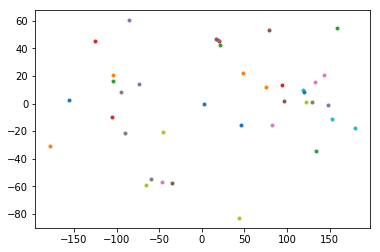

In [6]:
for result in results:
    
    plt.figure()
    for point in zip(*result[1])[1]:
        plt.plot(point.to_lat_lon()[1], point.to_lat_lon()[0], '.')
        
    plt.show()
    break
    


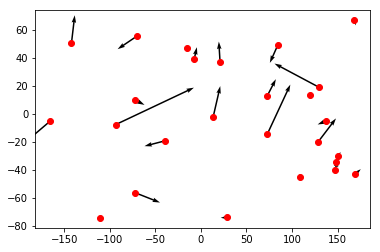

In [7]:
for result in results[5:6]:
    
    plt.figure()
    for point,vel in zip(zip(*result[1])[1],zip(*result[1])[4]):
        if vel is not None:
            plt.plot(point.to_lat_lon()[1], point.to_lat_lon()[0], 'ro')
            plt.quiver(point.to_lat_lon()[1],
                       point.to_lat_lon()[0],
                       vel.get_y(),
                       vel.get_x(),
                       color='k', units='xy', scale=0.02, width=1.5)
    break

In [8]:
target_plate_id = 301
reconstruction_time = 10

snapshot = M2016.plate_snapshot(reconstruction_time)

forces = {'slab_pull': 1}
result = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time,
                                              forces)
    
print pygplates.PointOnSphere(result[2].to_normalised().to_xyz()).to_lat_lon()

forces = {'slab_suction': 1}
result = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time,
                                              forces)
    
print pygplates.PointOnSphere(result[2].to_normalised().to_xyz()).to_lat_lon()


(57.10020788731055, 123.35880402521143)
(1.935133611632355, 165.7418678193773)


Unable to find the overriding plate of the subducting shared sub-segment "So Melanesian-MG-5-20-07"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "So Melanesian-MG-5-20-07"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "So Melanesian-MG-5-20-07"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate o

unable to plot vector for plate 925
unable to plot vector for plate 923


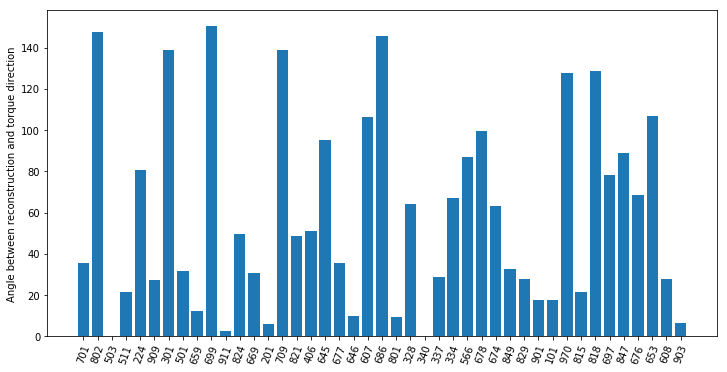

In [11]:
reconstruction_time = 0.
forces = {'slab_pull': 1,'slab_suction': 0.25, 'ridge_push':0.1}
#forces = {'ridge_push': 1}

snapshot = M2016.plate_snapshot(reconstruction_time)

result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)

plate_ids = []
angles = []

for res in result:
    if res[4] is not None:
        try:
            angle = pygplates.Vector3D.angle_between(res[4],res[6])
            plate_ids.append(res[0])
            angles.append(np.degrees(angle))
        except:
            print 'unable to plot vector for plate %d' % res[0]
    
    
width = 0.8
fig, ax = plt.subplots(figsize=(12,6))
plt.bar(np.arange(len(angles)),angles)
ax.set_xticks(np.arange(len(angles)))
ax.set_xticklabels(plate_ids,rotation=70)
plt.ylabel('Angle between reconstruction and torque direction')
plt.show()
        

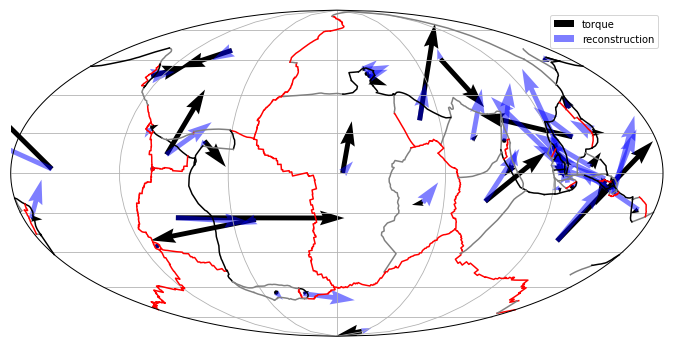

In [10]:
plt.figure(figsize=(12,6))
ax = plt.axes(projection=ccrs.Mollweide())

for boundary in snapshot.resolved_topological_sections:
    shared_sub_segments = boundary.get_shared_sub_segments()
    for shared_sub_segment in shared_sub_segments:
        if shared_sub_segment.get_resolved_feature().get_geometry() is not None:
            if shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_subduction_zone:
                boundary_color = 'black'
            elif shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_mid_ocean_ridge:
                boundary_color = 'red'
            else:
                boundary_color = 'gray'
            ax.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                    shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],
                    transform=ccrs.Geodetic(), color=boundary_color)


# plot the predicted velocities
x = []; y = []; u = []; v = []
for point,vel in zip(zip(*result)[1],zip(*result)[4]):
    if vel is not None:
        x.append(point.to_lat_lon()[1])
        y.append(point.to_lat_lon()[0])
        u.append(vel.get_y())
        v.append(vel.get_x())
ax.quiver(np.array(x),
          np.array(y),
          np.array(u),
          np.array(v),
          transform=ccrs.PlateCarree(), color='black', label='torque')

# plot velocities according to the reconstruction
x = []; y = []; u = []; v = []
for point,vel in zip(zip(*result)[1],zip(*result)[6]):
    if vel is not None:
        x.append(point.to_lat_lon()[1])
        y.append(point.to_lat_lon()[0])
        u.append(vel.get_y())
        v.append(vel.get_x())
ax.quiver(np.array(x),
          np.array(y),
          np.array(u),
          np.array(v),
          transform=ccrs.PlateCarree(), color='blue', alpha=0.5, label='reconstruction')

ax.set_global()
ax.gridlines()
plt.legend()
plt.show()


Unable to find the overriding plate of the subducting shared sub-segment "So Melanesian-MG-5-20-07"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "So Melanesian-MG-5-20-07"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "So Melanesian-MG-5-20-07"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate o

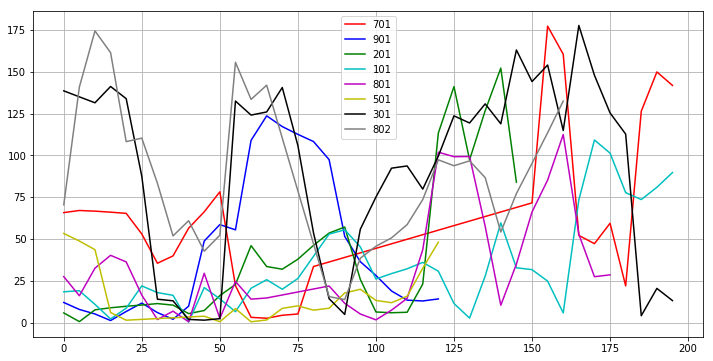

In [34]:
angle_701 = []; angle_901 = []; angle_201 = []; angle_101 = []; angle_801 = []; angle_501 = []; angle_301 = []; angle_802 = []

delta_time = 10.
forces = {'slab_pull': 1,'slab_suction': 0.25}

time_list = np.arange(0,200,5)

for reconstruction_time in time_list:

    snapshot = M2016.plate_snapshot(reconstruction_time)

    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)

    plate_ids = []
    angles = []

    for res in result:
        if res[4] is not None:
            if res[0]==701:
                angle_701.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==901:
                angle_901.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==201:
                angle_201.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==101:
                angle_101.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==801:
                angle_801.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==501:
                angle_501.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==301:
                angle_301.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==802:
                angle_802.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))

plt.figure(figsize=(12,6))
plt.plot(zip(*angle_701)[0],np.degrees(zip(*angle_701)[1]),'r', label=701)
plt.plot(zip(*angle_901)[0],np.degrees(zip(*angle_901)[1]),'b', label=901)
plt.plot(zip(*angle_201)[0],np.degrees(zip(*angle_201)[1]),'g', label=201)
plt.plot(zip(*angle_101)[0],np.degrees(zip(*angle_101)[1]),'c', label=101)
plt.plot(zip(*angle_801)[0],np.degrees(zip(*angle_801)[1]),'m', label=801)
plt.plot(zip(*angle_501)[0],np.degrees(zip(*angle_501)[1]),'y', label=501)
plt.plot(zip(*angle_301)[0],np.degrees(zip(*angle_301)[1]),'k', label=301)
plt.plot(zip(*angle_802)[0],np.degrees(zip(*angle_802)[1]),'grey', label=802)

plt.grid()
plt.legend()
                

Unable to find the overriding plate of the subducting shared sub-segment "Shirshov Ridge Subduction"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "Shirshov Ridge Subduction"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "Shirshov Ridge Subduction"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "Shirshov Ridge Subduction"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "Shirshov Ridge Subduction"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the o

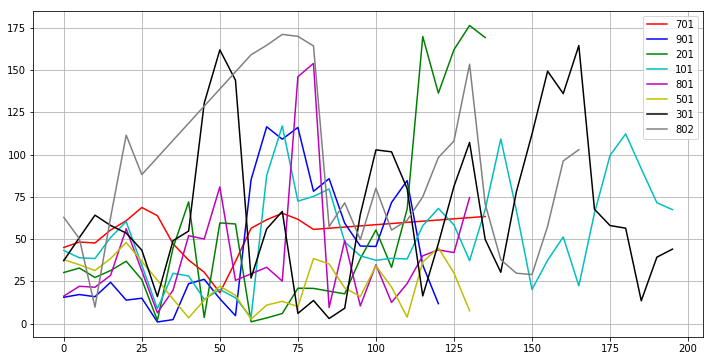

In [101]:
VDM = ReconstructionModel('VDM')
VDM.add_rotation_model('/Users/simon/Data/EByteSVN/EByteDeformingModels/Shephard_etal_2013_ESR/GPlates/Shephard_etal_ESR2013_Global_EarthByte_2013_VanDerMeer.rot')
VDM.add_static_polygons('/Users/simon/Data/EByteSVN/EByteDeformingModels/Shephard_etal_2013_ESR/GPlates/Shephard_etal_ESR2013_Global_staticpolygons.gpml')
VDM.add_dynamic_polygons('/Users/simon/Data/EByteSVN/EByteDeformingModels/Shephard_etal_2013_ESR/GPlates/Shephard_etal_ESR2013_Global_EarthByte_2013.gpml')

angle_701 = []; angle_901 = []; angle_201 = []; angle_101 = []; angle_801 = []; angle_501 = []; angle_301 = []; angle_802 = []

delta_time = 10.
forces = {'slab_pull': 1,'slab_suction': 0.25}

time_list = np.arange(0,200,5)

for reconstruction_time in time_list:

    snapshot = VDM.plate_snapshot(reconstruction_time)

    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time, forces)

    plate_ids = []
    angles = []

    for res in result:
        if res[4] is not None:
            if res[0]==701:
                angle_701.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==901:
                angle_901.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==201:
                angle_201.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==101:
                angle_101.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==801:
                angle_801.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==501:
                angle_501.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==301:
                angle_301.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))
            elif res[0]==802:
                angle_802.append((reconstruction_time,pygplates.Vector3D.angle_between(res[4],res[6])))

plt.figure(figsize=(12,6))
plt.plot(zip(*angle_701)[0],np.degrees(zip(*angle_701)[1]),'r', label=701)
plt.plot(zip(*angle_901)[0],np.degrees(zip(*angle_901)[1]),'b', label=901)
plt.plot(zip(*angle_201)[0],np.degrees(zip(*angle_201)[1]),'g', label=201)
plt.plot(zip(*angle_101)[0],np.degrees(zip(*angle_101)[1]),'c', label=101)
plt.plot(zip(*angle_801)[0],np.degrees(zip(*angle_801)[1]),'m', label=801)
plt.plot(zip(*angle_501)[0],np.degrees(zip(*angle_501)[1]),'y', label=501)
plt.plot(zip(*angle_301)[0],np.degrees(zip(*angle_301)[1]),'k', label=301)
plt.plot(zip(*angle_802)[0],np.degrees(zip(*angle_802)[1]),'grey', label=802)

plt.grid()
plt.legend()


In [178]:
forces = {'ridge_push': 1}

reconstruction_time = 50.
snapshot = M2016.plate_snapshot(reconstruction_time)

target_plate_id = 701


pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time, forces)


[701,

In [161]:
forces = {'slab_pull': 1, 'ridge_push': 0.1}

print 'slab_pull' in forces
print forces['slab_pull']
print int(True)

True
1
1
